In [11]:
from pathlib import Path
import pandas as pd

csv_path = Path("Methane_steam_reforming_data.csv")
df = pd.read_csv(csv_path)

display(df.head())
print(f"Rows: {len(df)}, columns: {len(df.columns)}")

,temperature_K,pressure_bar,coverage_CH,coverage_C,coverage_OH,coverage_O,coverage_CO,TOF_s-1
0,1273.956049,14.527309,0.016876,0.031758,0.041048,0.055860,0.086677,129.813774
1,938.878440,13.605462,0.059070,0.103541,0.158560,0.034221,0.334023,1.556174
2,1358.597920,0.405588,0.012706,0.013252,0.007455,0.003808,0.019291,18.735156
3,1197.368029,0.128815,0.021609,0.020646,0.075593,0.018774,0.017159,2.949186
4,594.177348,0.815452,0.060411,0.131648,0.120725,0.221140,0.361895,0.000041


Rows: 10000, columns: 8


Dataset shape: (10000, 8)

First five rows:
   temperature_K  pressure_bar  coverage_CH  coverage_C  coverage_OH  \
0    1273.956049     14.527309     0.016876    0.031758     0.041048   
1     938.878440     13.605462     0.059070    0.103541     0.158560   
2    1358.597920      0.405588     0.012706    0.013252     0.007455   
3    1197.368029      0.128815     0.021609    0.020646     0.075593   
4     594.177348      0.815452     0.060411    0.131648     0.120725   

   coverage_O  coverage_CO     TOF_s-1  
0    0.055860     0.086677  129.813774  
1    0.034221     0.334023    1.556174  
2    0.003808     0.019291   18.735156  
3    0.018774     0.017159    2.949186  
4    0.221140     0.361895    0.000041  

Training rows: 8000
Reserved test rows: 2000


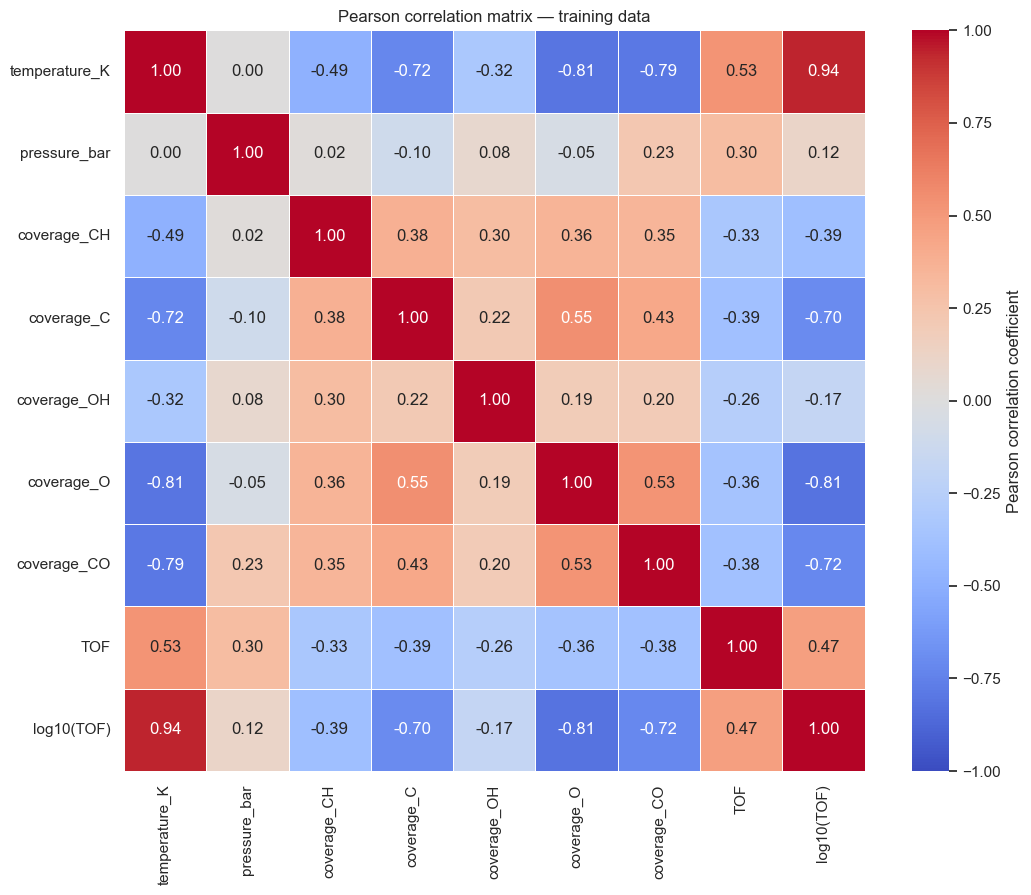


Feature associations with TOF:
               Pearson_r  Absolute_Pearson_r  Mutual_information
Feature                                                         
temperature_K     0.5264              0.5264              0.9401
coverage_O       -0.3629              0.3629              0.6082
coverage_C       -0.3888              0.3888              0.4926
coverage_CO      -0.3795              0.3795              0.4312
coverage_CH      -0.3290              0.3290              0.2147
pressure_bar      0.3026              0.3026              0.1425
coverage_OH      -0.2590              0.2590              0.1133

Feature associations with log10(TOF):
               Pearson_r  Absolute_Pearson_r  Mutual_information
Feature                                                         
temperature_K     0.9409              0.9409              1.4025
coverage_O       -0.8145              0.8145              0.6726
coverage_C       -0.7015              0.7015              0.5194
coverage_CO      -0

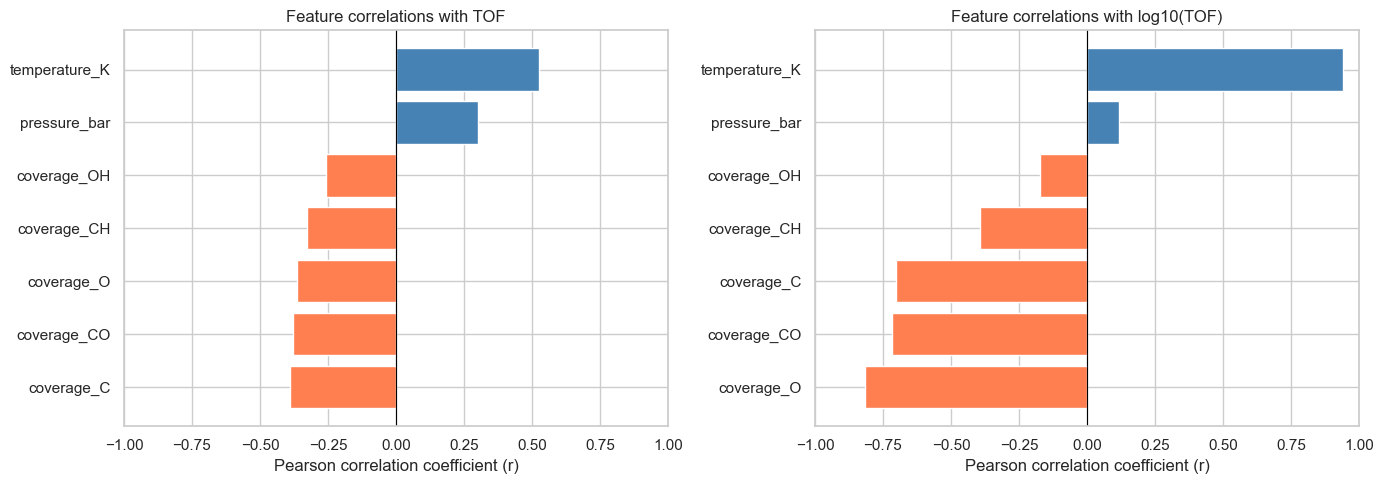

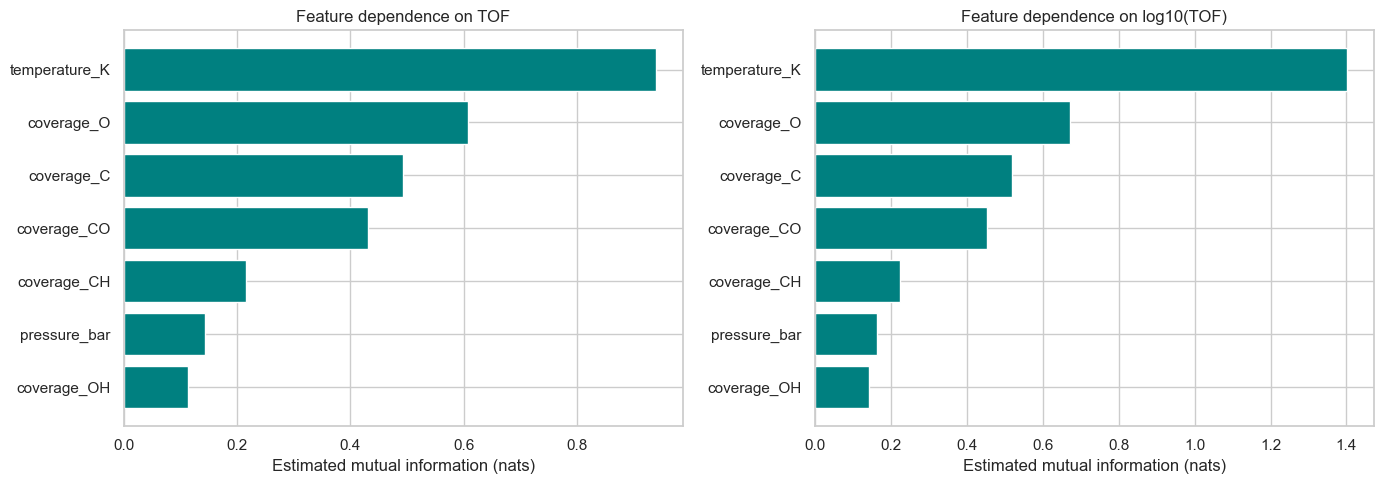


Plots and results saved in: C:\Users\saish\Desktop\Desktop Stuff\ML_AI_projects\Microkinetic_data\feature_analysis_outputs


In [12]:
# =====================================================================
# FEATURE ASSOCIATION ANALYSIS: METHANE STEAM REFORMING
# =====================================================================
#
# PURPOSE
# -------
# Examine how temperature, pressure, and surface coverages relate to
# turnover frequency (TOF) before fitting machine learning models.
#
# INPUT FILE
# ----------
# methane_steam_reforming_data.csv
#
# Features:
#   temperature_K : Temperature in kelvin.
#   pressure_bar  : Total pressure in bar.
#   coverage_CH   : Fractional surface coverage of CH.
#   coverage_C    : Fractional surface coverage of C.
#   coverage_OH   : Fractional surface coverage of OH.
#   coverage_O    : Fractional surface coverage of O.
#   coverage_CO   : Fractional surface coverage of CO.
#
# Target:
#   TOF_s-1       : Turnover frequency in inverse seconds.
#
# METHODS
# -------
# 1. Pearson correlation:
#    Measures the strength and direction of a linear relationship.
#    Values range from -1 to +1:
#      +1 : Perfect positive linear relationship.
#       0 : No linear correlation; nonlinear dependence may still exist.
#      -1 : Perfect negative linear relationship.
#
# 2. Mutual information (MI):
#    Measures dependence, including nonlinear relationships.
#    Higher scores indicate stronger dependence.
#    Scores have no direction and are not restricted to [0, 1].
#    Estimates are reported in nats and depend on estimator settings.
#    An estimated score of zero does not prove independence.
#
# TARGET TRANSFORMATION
# ---------------------
# Analyse both TOF and log10(TOF), since TOF spans several orders of
# magnitude. Taking the logarithm reduces the influence of large values.
# TOF must be strictly positive for this transformation.
#
# Pearson correlations can change after taking logarithms.
# Theoretical MI is invariant under an invertible transformation, but
# numerical MI estimates can differ between TOF and log10(TOF).
#
# TRAIN/TEST SPLIT
# ----------------
# Use 80% of the data for feature analysis and reserve 20% for subsequent
# model testing. Do not use the test subset for feature selection.
# random_state=42 makes the split reproducible.
#
# OUTPUTS
# -------
# pearson_correlation_heatmap.png
# pearson_feature_correlations.png
# mutual_information_scores.png
# feature_association_results.csv
#
# LIMITATIONS
# -----------
# These scores measure individual feature associations, rather than
# importance within a fitted regression model.
# Correlated features can contain overlapping information, and surface
# coverages are constrained by the available number of sites.
# Associations do not establish causation or independent feature effects.
# Features with low individual scores may still contribute via interactions.
# Results describe this generated practice dataset, rather than validated
# real-catalyst behaviour.
#
# DEPENDENCIES
# ------------
# Run in a terminal if necessary:
# pip install pandas numpy matplotlib seaborn scikit-learn
# =====================================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import train_test_split


# ---------------------------------------------------------------------
# 1. Settings
# ---------------------------------------------------------------------
INPUT_FILE = Path("methane_steam_reforming_data.csv")
OUTPUT_DIR = Path("feature_analysis_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

features = [
    "temperature_K",
    "pressure_bar",
    "coverage_CH",
    "coverage_C",
    "coverage_OH",
    "coverage_O",
    "coverage_CO",
]

target = "TOF_s-1"

sns.set_theme(style="whitegrid", context="notebook")


# ---------------------------------------------------------------------
# 2. Load and validate the dataset
# ---------------------------------------------------------------------
df = pd.read_csv(INPUT_FILE)

required_columns = features + [target]
missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

# Raise an error if any required value cannot be converted to a number.
data = df[required_columns].apply(pd.to_numeric, errors="raise")

if not np.isfinite(data.to_numpy()).all():
    raise ValueError("The dataset contains missing or infinite values.")

if (data[target] <= 0).any():
    raise ValueError("TOF must be positive for the log10 transformation.")

if (data[features].nunique() < 2).any():
    raise ValueError("All features must contain at least two distinct values.")

print(f"Dataset shape: {data.shape}")
print("\nFirst five rows:")
print(data.head())


# ---------------------------------------------------------------------
# 3. Split the data
# ---------------------------------------------------------------------
# Only the training subset is used in the following association analysis.
train, test = train_test_split(
    data,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

X = train[features].copy()

targets = {
    "TOF": train[target],
    "log10(TOF)": np.log10(train[target]),
}

print(f"\nTraining rows: {len(train)}")
print(f"Reserved test rows: {len(test)}")


# ---------------------------------------------------------------------
# 4. Calculate and plot the Pearson correlation matrix
# ---------------------------------------------------------------------
# Include both target representations to compare their relationships
# with the inputs. Feature–feature correlations reveal redundancy.
correlation_data = X.copy()
correlation_data["TOF"] = targets["TOF"]
correlation_data["log10(TOF)"] = targets["log10(TOF)"]

correlation_matrix = correlation_data.corr(method="pearson")

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson correlation coefficient"},
    ax=ax,
)

ax.set_title("Pearson correlation matrix — training data")
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "pearson_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


# ---------------------------------------------------------------------
# 5. Calculate feature–target Pearson correlations and MI scores
# ---------------------------------------------------------------------
results = {}

for target_name, y in targets.items():

    # Signed Pearson correlation for each feature against the target.
    pearson = X.corrwith(y, method="pearson")

    # Estimate MI for continuous features and a continuous target.
    # n_neighbors controls the estimation smoothness.
    mi = mutual_info_regression(
        X,
        y,
        discrete_features=False,
        n_neighbors=5,
        random_state=RANDOM_STATE,
    )

    scores = pd.DataFrame(
        {
            "Pearson_r": pearson.to_numpy(),
            "Absolute_Pearson_r": pearson.abs().to_numpy(),
            "Mutual_information": mi,
        },
        index=pd.Index(features, name="Feature"),
    )

    results[target_name] = scores

    print(f"\nFeature associations with {target_name}:")
    print(
        scores.sort_values(
            "Mutual_information",
            ascending=False,
        ).round(4)
    )


# ---------------------------------------------------------------------
# 6. Plot signed Pearson correlations with each target
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (target_name, scores) in zip(axes, results.items()):

    values = scores["Pearson_r"].sort_values()
    colors = [
        "steelblue" if value >= 0 else "coral"
        for value in values
    ]

    ax.barh(values.index, values.values, color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlim(-1, 1)
    ax.set_xlabel("Pearson correlation coefficient (r)")
    ax.set_title(f"Feature correlations with {target_name}")

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "pearson_feature_correlations.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


# ---------------------------------------------------------------------
# 7. Plot mutual information scores with each target
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (target_name, scores) in zip(axes, results.items()):

    values = scores["Mutual_information"].sort_values()

    ax.barh(values.index, values.values, color="teal")
    ax.set_xlabel("Estimated mutual information (nats)")
    ax.set_title(f"Feature dependence on {target_name}")
    ax.set_xlim(left=0)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "mutual_information_scores.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


# ---------------------------------------------------------------------
# 8. Save the numerical results
# ---------------------------------------------------------------------
# Each row identifies the target representation and the input feature.
summary = pd.concat(
    results,
    names=["Target", "Feature"],
)

summary.to_csv(
    OUTPUT_DIR / "feature_association_results.csv"
)

print(f"\nPlots and results saved in: {OUTPUT_DIR.resolve()}")


Results for each fold:
      Train_rows  Test_rows  Train_R2  Train_MAE  Train_RMSE  Test_R2  Test_MAE  Test_RMSE
Fold                                                                                      
1           9000       1000    0.9220     0.5856      0.7297   0.9239    0.6004     0.7359
2           9000       1000    0.9223     0.5870      0.7304   0.9215    0.5878     0.7307
3           9000       1000    0.9231     0.5836      0.7276   0.9141    0.6174     0.7547
4           9000       1000    0.9221     0.5861      0.7294   0.9234    0.5933     0.7387
5           9000       1000    0.9222     0.5870      0.7311   0.9228    0.5864     0.7237
6           9000       1000    0.9220     0.5889      0.7329   0.9240    0.5711     0.7073
7           9000       1000    0.9222     0.5883      0.7316   0.9223    0.5744     0.7190
8           9000       1000    0.9222     0.5855      0.7288   0.9224    0.5977     0.7445
9           9000       1000    0.9216     0.5897      0.7326   0.9

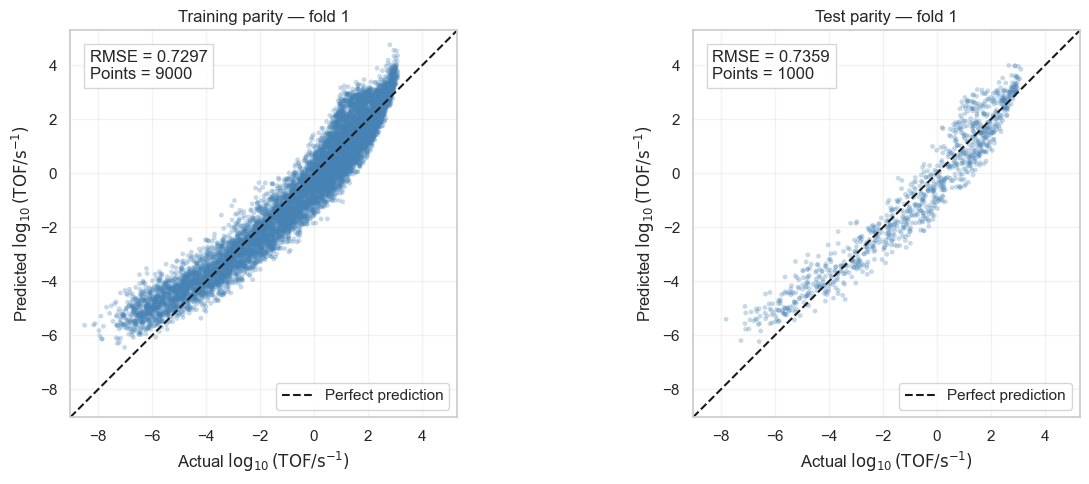


Results saved in: C:\Users\saish\Desktop\Desktop Stuff\ML_AI_projects\Microkinetic_data\linear_regression_outputs


In [13]:
# =====================================================================
# LINEAR REGRESSION WITH 10-FOLD CROSS-VALIDATION
# =====================================================================
#
# INPUT
# -----
# methane_steam_reforming_data.csv
#
# FEATURES
# --------
# Temperature, pressure, and CH, C, OH, O, CO surface coverages.
#
# TARGET
# ------
# USE_LOG_TARGET = True  : Predict log10(TOF).
# USE_LOG_TARGET = False : Predict TOF directly.
#
# TRAIN/TEST SPLIT
# ----------------
# Each fold uses 90% of the data for training and 10% for testing.
# For 10,000 rows: 9,000 training rows and 1,000 test rows per fold.
# Every row appears in a test fold exactly once.
# "Test" refers to the held-out cross-validation fold.
# There is no additional independent test set.
#
# PREPROCESSING
# -------------
# StandardScaler is fitted only on the training data within each fold.
# A Pipeline prevents information from the test fold entering scaling.
#
# METRICS
# -------
# R2   : Higher is better; can be negative.
# MAE  : Mean absolute error; lower is better.
# RMSE : Root mean squared error; lower is better.
#
# When predicting log10(TOF), MAE and RMSE are in log10 units.
# When predicting TOF directly, MAE and RMSE are in s^-1.
#
# PARITY PLOTS
# ------------
# Training: predictions for the training data from fold 1.
# Test: combined out-of-fold predictions for all 10,000 rows.
# The dashed diagonal indicates perfect predictions.
#
# LIMITATIONS
# -----------
# Random-fold testing evaluates interpolation within this dataset.
# It does not establish accuracy outside the sampled operating range.
#
# Install dependencies if needed:
# pip install pandas numpy matplotlib scikit-learn
# =====================================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
)
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ---------------------------------------------------------------------
# 1. Settings
# ---------------------------------------------------------------------
INPUT_FILE = Path("methane_steam_reforming_data.csv")
OUTPUT_DIR = Path("linear_regression_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

USE_LOG_TARGET = True
RANDOM_STATE = 42

features = [
    "temperature_K",
    "pressure_bar",
    "coverage_CH",
    "coverage_C",
    "coverage_OH",
    "coverage_O",
    "coverage_CO",
]

target = "TOF_s-1"


# ---------------------------------------------------------------------
# 2. Load and check data
# ---------------------------------------------------------------------
df = pd.read_csv(INPUT_FILE)

missing_columns = set(features + [target]) - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")

data = df[features + [target]].apply(pd.to_numeric, errors="raise")

if not np.isfinite(data.to_numpy()).all():
    raise ValueError("The dataset contains missing or infinite values.")

if len(data) < 10:
    raise ValueError("At least 10 rows are required.")

X = data[features]
tof = data[target].to_numpy()

if USE_LOG_TARGET:
    if (tof <= 0).any():
        raise ValueError("TOF must be positive for log10 transformation.")

    y = np.log10(tof)
    target_label = r"$\log_{10}(\mathrm{TOF}/\mathrm{s}^{-1})$"
else:
    y = tof.copy()
    target_label = r"TOF ($\mathrm{s}^{-1}$)"


# ---------------------------------------------------------------------
# 3. Define model and metric functions
# ---------------------------------------------------------------------
def make_model():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", LinearRegression()),
    ])


def calculate_metrics(actual, predicted):
    return {
        "R2": r2_score(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
    }


cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=RANDOM_STATE,
)

oof_predictions = np.full(len(y), np.nan)
fold_assignments = np.zeros(len(y), dtype=int)
fold_results = []

example_train_actual = None
example_train_predicted = None


# ---------------------------------------------------------------------
# 4. Run 10-fold cross-validation
# ---------------------------------------------------------------------
for fold, (train_idx, test_idx) in enumerate(cv.split(X), start=1):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y[train_idx]
    y_test = y[test_idx]

    model = make_model()
    model.fit(X_train, y_train)

    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    train_metrics = calculate_metrics(y_train, train_predictions)
    test_metrics = calculate_metrics(y_test, test_predictions)

    oof_predictions[test_idx] = test_predictions
    fold_assignments[test_idx] = fold

    fold_results.append({
        "Fold": fold,
        "Train_rows": len(train_idx),
        "Test_rows": len(test_idx),
        "Train_R2": train_metrics["R2"],
        "Train_MAE": train_metrics["MAE"],
        "Train_RMSE": train_metrics["RMSE"],
        "Test_R2": test_metrics["R2"],
        "Test_MAE": test_metrics["MAE"],
        "Test_RMSE": test_metrics["RMSE"],
    })

    if fold == 1:
        example_train_actual = y_train.copy()
        example_train_predicted = train_predictions.copy()


# ---------------------------------------------------------------------
# 5. Report training and test metrics
# ---------------------------------------------------------------------
fold_results = pd.DataFrame(fold_results).set_index("Fold")

print("\nResults for each fold:")
print(fold_results.round(4).to_string())

metric_columns = [
    "Train_R2", "Train_MAE", "Train_RMSE",
    "Test_R2", "Test_MAE", "Test_RMSE",
]

summary = fold_results[metric_columns].agg(["mean", "std"]).T
summary.columns = ["Mean", "Standard_deviation"]

print("\nMean and standard deviation across 10 folds:")
print(summary.round(4).to_string())

# Pooled test metrics use one held-out prediction for every row.
# They can differ from the average of the individual fold metrics.
pooled_test_metrics = calculate_metrics(y, oof_predictions)

print("\nPooled out-of-fold test metrics:")
for name, value in pooled_test_metrics.items():
    print(f"{name}: {value:.4f}")


# ---------------------------------------------------------------------
# 6. Plot training and test parity for fold 1 only
# ---------------------------------------------------------------------
# Training predictions for fold 1 were stored during cross-validation.
# Extract test predictions belonging only to fold 1.
test_mask = fold_assignments == 1

fold_test_actual = y[test_mask]
fold_test_predicted = oof_predictions[test_mask]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_data = [
    (
        example_train_actual,
        example_train_predicted,
        "Training parity — fold 1",
    ),
    (
        fold_test_actual,
        fold_test_predicted,
        "Test parity — fold 1",
    ),
]

# Shared axis limits for easier comparison.
all_values = np.concatenate([
    example_train_actual,
    example_train_predicted,
    fold_test_actual,
    fold_test_predicted,
])

lower = all_values.min()
upper = all_values.max()
padding = 0.04 * (upper - lower) if upper > lower else 1.0
limits = [lower - padding, upper + padding]

for ax, (actual, predicted, title) in zip(axes, plot_data):

    rmse = np.sqrt(mean_squared_error(actual, predicted))

    ax.scatter(
        actual,
        predicted,
        s=12,
        alpha=0.3,
        color="steelblue",
        edgecolors="none",
    )

    ax.plot(
        limits,
        limits,
        "k--",
        linewidth=1.5,
        label="Perfect prediction",
    )

    ax.text(
        0.05,
        0.95,
        f"RMSE = {rmse:.4f}\nPoints = {len(actual)}",
        transform=ax.transAxes,
        va="top",
        bbox=dict(
            facecolor="white",
            alpha=0.9,
            edgecolor="lightgray",
        ),
    )

    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(f"Actual {target_label}")
    ax.set_ylabel(f"Predicted {target_label}")
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(loc="lower right")

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "linear_regression_fold1_parity.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


# ---------------------------------------------------------------------
# 7. Save metrics and out-of-fold test predictions
# ---------------------------------------------------------------------
fold_results.to_csv(OUTPUT_DIR / "cv_fold_metrics.csv")
summary.to_csv(OUTPUT_DIR / "cv_metrics_summary.csv")

prediction_results = pd.DataFrame({
    "Row_index": data.index,
    "Test_fold": fold_assignments,
})

if USE_LOG_TARGET:
    prediction_results["Actual_log10_TOF"] = y
    prediction_results["Test_predicted_log10_TOF"] = oof_predictions
    prediction_results["Actual_TOF_s-1"] = tof

    # Back-transformed predictions are not bias-corrected estimates
    # of the conditional mean TOF.
    prediction_results["Test_predicted_TOF_s-1"] = (
        10.0 ** oof_predictions
    )
else:
    prediction_results["Actual_TOF_s-1"] = y
    prediction_results["Test_predicted_TOF_s-1"] = oof_predictions

prediction_results.to_csv(
    OUTPUT_DIR / "out_of_fold_test_predictions.csv",
    index=False,
)


# ---------------------------------------------------------------------
# 8. Fit the final model on all available data
# ---------------------------------------------------------------------
# Use this model for future predictions. Report the cross-validation
# scores above when describing its estimated predictive performance.
final_model = make_model()
final_model.fit(X, y)

print(f"\nResults saved in: {OUTPUT_DIR.resolve()}")

Dataset shape: (10000, 8)
Target: log10(TOF)

Parameter combinations: 9
Folds per combination: 10

Results — lowest average test RMSE first:
max_depth  min_samples_leaf  Mean_train_RMSE  Mean_test_RMSE
     None                20           0.2630          0.3230
       10                20           0.2639          0.3234
       10                 5           0.2093          0.3264
     None                 5           0.1730          0.3279
       10                 1           0.1920          0.3378
     None                 1           0.0000          0.3620
        5                 1           0.3935          0.4096
        5                 5           0.3935          0.4096
        5                20           0.3935          0.4096

SELECTED HYPERPARAMETERS
{'max_depth': None, 'min_samples_leaf': 20}
Average train RMSE: 0.2630
Average test RMSE:  0.3230

FOLD 1 RESULTS
Training rows: 9000
Test rows: 1000
Train RMSE: 0.2622
Test RMSE:  0.3316


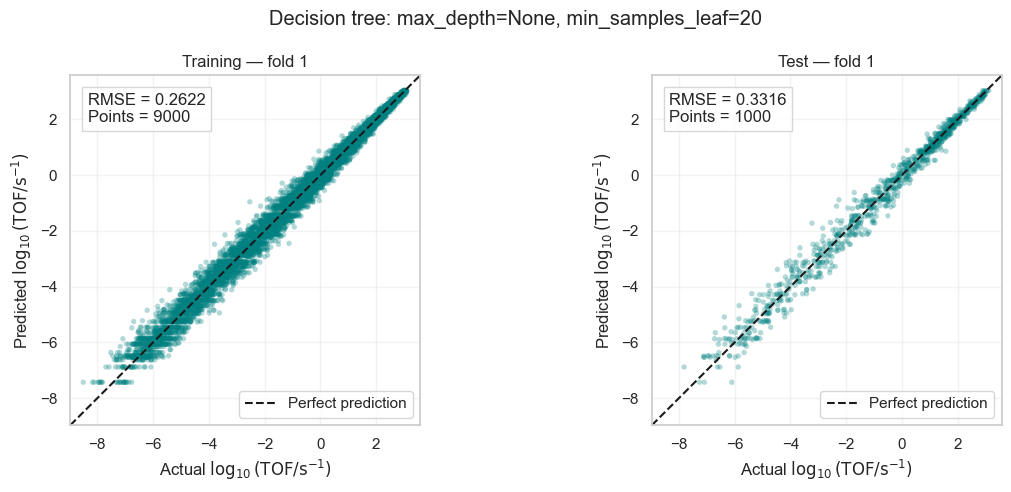


Final model fitted on all rows.
Selected hyperparameters: {'max_depth': None, 'min_samples_leaf': 20}
Actual tree depth: 12
Number of leaves: 384
Results saved in: C:\Users\saish\Desktop\Desktop Stuff\ML_AI_projects\Microkinetic_data\decision_tree_outputs


In [8]:
# =====================================================================
# DECISION TREE REGRESSION: SIMPLE HYPERPARAMETER TUNING
# =====================================================================
#
# PURPOSE
# -------
# Predict turnover frequency (TOF) from temperature, pressure, and
# surface coverages using a decision tree regressor.
#
# HYPERPARAMETER SEARCH
# ---------------------
# Test nine combinations:
#   max_depth        : [5, 10, None]
#   min_samples_leaf : [1, 5, 20]
#
# max_depth controls the maximum depth of the tree.
# None allows unrestricted depth, subject to other stopping conditions.
#
# min_samples_leaf sets the minimum training points in each leaf.
# Larger values can reduce overfitting.
#
# CROSS-VALIDATION
# ----------------
# Evaluate each combination using the same shuffled 10-fold split.
# For 10,000 rows, each fold uses:
#   9,000 training rows.
#   1,000 test rows.
#
# Calculate train and test RMSE in each fold, then average across folds.
# Select the combination with the LOWEST AVERAGE TEST RMSE.
#
# TARGET
# ------
# USE_LOG_TARGET=True  : Predict log10(TOF); RMSE is in log10 units.
# USE_LOG_TARGET=False : Predict TOF directly; RMSE is in s^-1.
#
# PARITY PLOTS
# ------------
# Show training and test predictions for fold 1 using the selected
# hyperparameters. Plot RMSE values apply to fold 1, not all ten folds.
#
# FINAL MODEL
# -----------
# Fit the selected configuration on all rows for future predictions.
# A separate fold model is used for the parity plots.
#
# NOTE
# ----
# The test folds also select hyperparameters, so their scores are tuning
# estimates rather than independent final test scores.
# Feature scaling is unnecessary for decision trees.
#
# Dependencies:
# pip install pandas numpy matplotlib scikit-learn
# =====================================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import KFold, ParameterGrid
from sklearn.metrics import mean_squared_error


# ---------------------------------------------------------------------
# 1. Settings
# ---------------------------------------------------------------------
INPUT_FILE = Path("methane_steam_reforming_data.csv")

OUTPUT_DIR = Path("decision_tree_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

USE_LOG_TARGET = True
RANDOM_STATE = 42

features = [
    "temperature_K",
    "pressure_bar",
    "coverage_CH",
    "coverage_C",
    "coverage_OH",
    "coverage_O",
    "coverage_CO",
]

target = "TOF_s-1"


# ---------------------------------------------------------------------
# 2. Load and check data
# ---------------------------------------------------------------------
df = pd.read_csv(INPUT_FILE)

missing_columns = set(features + [target]) - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")

data = df[features + [target]].apply(pd.to_numeric, errors="raise")

X = data[features].to_numpy(dtype=float)
y = data[target].to_numpy(dtype=float)

if not np.isfinite(X).all() or not np.isfinite(y).all():
    raise ValueError("Data contain missing or infinite values.")

if len(data) < 20:
    raise ValueError("At least 20 rows are required for this CV setup.")

if USE_LOG_TARGET:
    if (y <= 0).any():
        raise ValueError("TOF must be positive for log10 transformation.")
    y = np.log10(y)

print(f"Dataset shape: {data.shape}")
print("Target:", "log10(TOF)" if USE_LOG_TARGET else "TOF")


# ---------------------------------------------------------------------
# 3. Define hyperparameter combinations and 10-fold splits
# ---------------------------------------------------------------------
param_grid = {
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 5, 20],
}

parameter_combinations = list(ParameterGrid(param_grid))

cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=RANDOM_STATE,
)

# Reuse identical folds for every combination.
splits = list(cv.split(X))

print(f"\nParameter combinations: {len(parameter_combinations)}")
print(f"Folds per combination: {len(splits)}")


# ---------------------------------------------------------------------
# 4. Evaluate each combination
# ---------------------------------------------------------------------
results = []

for combination_id, params in enumerate(parameter_combinations):
    train_rmse_scores = []
    test_rmse_scores = []

    for train_idx, test_idx in splits:
        model = DecisionTreeRegressor(
            **params,
            random_state=RANDOM_STATE,
        )

        model.fit(X[train_idx], y[train_idx])

        train_predictions = model.predict(X[train_idx])
        test_predictions = model.predict(X[test_idx])

        train_rmse = np.sqrt(
            mean_squared_error(y[train_idx], train_predictions)
        )
        test_rmse = np.sqrt(
            mean_squared_error(y[test_idx], test_predictions)
        )

        train_rmse_scores.append(train_rmse)
        test_rmse_scores.append(test_rmse)

    results.append({
        "Combination": combination_id,
        "max_depth": (
            "None"
            if params["max_depth"] is None
            else params["max_depth"]
        ),
        "min_samples_leaf": params["min_samples_leaf"],
        "Mean_train_RMSE": np.mean(train_rmse_scores),
        "Mean_test_RMSE": np.mean(test_rmse_scores),
    })


# ---------------------------------------------------------------------
# 5. Rank combinations and select the lowest average test RMSE
# ---------------------------------------------------------------------
results_df = (
    pd.DataFrame(results)
    .sort_values("Mean_test_RMSE", kind="stable")
    .reset_index(drop=True)
)

print("\nResults — lowest average test RMSE first:")
print(
    results_df.drop(columns="Combination")
    .round(4)
    .to_string(index=False)
)

best_result = results_df.iloc[0]
best_params = parameter_combinations[
    int(best_result["Combination"])
]

print("\nSELECTED HYPERPARAMETERS")
print(best_params)

print(
    f"Average train RMSE: "
    f"{best_result['Mean_train_RMSE']:.4f}"
)
print(
    f"Average test RMSE:  "
    f"{best_result['Mean_test_RMSE']:.4f}"
)

results_df.drop(columns="Combination").to_csv(
    OUTPUT_DIR / "hyperparameter_results.csv",
    index=False,
)


# ---------------------------------------------------------------------
# 6. Fit fold 1 using the selected hyperparameters
# ---------------------------------------------------------------------
train_idx, test_idx = splits[0]

fold_model = DecisionTreeRegressor(
    **best_params,
    random_state=RANDOM_STATE,
)

fold_model.fit(X[train_idx], y[train_idx])

train_predictions = fold_model.predict(X[train_idx])
test_predictions = fold_model.predict(X[test_idx])

fold_train_rmse = np.sqrt(
    mean_squared_error(y[train_idx], train_predictions)
)
fold_test_rmse = np.sqrt(
    mean_squared_error(y[test_idx], test_predictions)
)

print("\nFOLD 1 RESULTS")
print(f"Training rows: {len(train_idx)}")
print(f"Test rows: {len(test_idx)}")
print(f"Train RMSE: {fold_train_rmse:.4f}")
print(f"Test RMSE:  {fold_test_rmse:.4f}")


# ---------------------------------------------------------------------
# 7. Plot training and test parity for fold 1
# ---------------------------------------------------------------------
target_label = (
    r"$\log_{10}(\mathrm{TOF}/\mathrm{s}^{-1})$"
    if USE_LOG_TARGET
    else r"TOF ($\mathrm{s}^{-1}$)"
)

# Shared limits make the training and test plots directly comparable.
all_values = np.concatenate([
    y[train_idx],
    y[test_idx],
    train_predictions,
    test_predictions,
])

lower = all_values.min()
upper = all_values.max()
padding = 0.04 * (upper - lower) if upper > lower else 1.0
limits = [lower - padding, upper + padding]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_data = [
    (
        y[train_idx],
        train_predictions,
        fold_train_rmse,
        "Training — fold 1",
    ),
    (
        y[test_idx],
        test_predictions,
        fold_test_rmse,
        "Test — fold 1",
    ),
]

for ax, (actual, predicted, rmse, title) in zip(axes, plot_data):
    ax.scatter(
        actual,
        predicted,
        s=15,
        alpha=0.3,
        color="teal",
        edgecolors="none",
    )

    ax.plot(
        limits,
        limits,
        "k--",
        linewidth=1.5,
        label="Perfect prediction",
    )

    ax.text(
        0.05,
        0.95,
        f"RMSE = {rmse:.4f}\nPoints = {len(actual)}",
        transform=ax.transAxes,
        va="top",
        bbox=dict(
            facecolor="white",
            alpha=0.9,
            edgecolor="lightgray",
        ),
    )

    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(f"Actual {target_label}")
    ax.set_ylabel(f"Predicted {target_label}")
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(loc="lower right")

fig.suptitle(
    "Decision tree: "
    f"max_depth={best_params['max_depth']}, "
    f"min_samples_leaf={best_params['min_samples_leaf']}"
)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "selected_parameters_fold1_parity.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


# ---------------------------------------------------------------------
# 8. Fit the final model on all available data
# ---------------------------------------------------------------------
final_model = DecisionTreeRegressor(
    **best_params,
    random_state=RANDOM_STATE,
)

final_model.fit(X, y)

print("\nFinal model fitted on all rows.")
print(f"Selected hyperparameters: {best_params}")
print(f"Actual tree depth: {final_model.get_depth()}")
print(f"Number of leaves: {final_model.get_n_leaves()}")
print(f"Results saved in: {OUTPUT_DIR.resolve()}")

# Future predictions:
# predicted_target = final_model.predict(new_data[features].to_numpy())
#
# If USE_LOG_TARGET=True, convert predictions back to TOF:
# predicted_tof = 10.0 ** predicted_target

Dataset shape: (10000, 8)
Target: log10(TOF)

Parameter combinations: 8
Folds per combination: 10

Combination 1/8: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 100}
Average train RMSE: 0.1629 | Average test RMSE: 0.2644

Combination 2/8: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 200}
Average train RMSE: 0.1624 | Average test RMSE: 0.2637

Combination 3/8: {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 100}
Average train RMSE: 0.1865 | Average test RMSE: 0.2652

Combination 4/8: {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 200}
Average train RMSE: 0.1860 | Average test RMSE: 0.2647

Combination 5/8: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
Average train RMSE: 0.0957 | Average test RMSE: 0.2557

Combination 6/8: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Average train RMSE: 0.0946 | Average test RMSE: 0.2544

Combination 7/8: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 100}
Averag

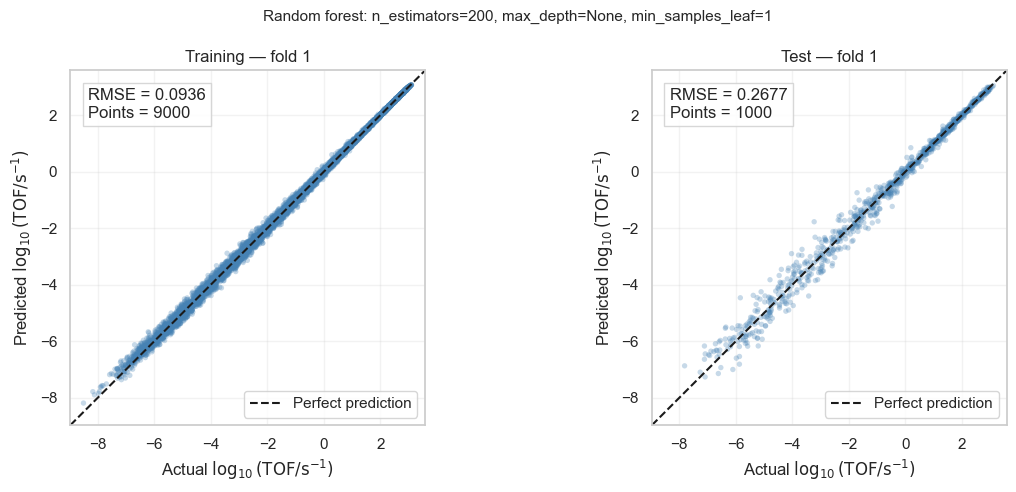


Final model fitted on all rows.
Selected hyperparameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Results saved in: C:\Users\saish\Desktop\Desktop Stuff\ML_AI_projects\Microkinetic_data\random_forest_outputs


In [9]:
# =====================================================================
# RANDOM FOREST REGRESSION: SIMPLE HYPERPARAMETER TUNING
# =====================================================================
#
# PURPOSE
# -------
# Predict turnover frequency (TOF) using temperature, pressure, and
# surface coverages.
#
# HYPERPARAMETER SEARCH
# ---------------------
# Test eight combinations:
#   n_estimators     : [100, 200]
#   max_depth        : [10, None]
#   min_samples_leaf : [1, 5]
#
# n_estimators:
#   Number of trees in the forest. More trees generally stabilise
#   predictions but increase computation time.
#
# max_depth:
#   Maximum depth of each tree.
#   None allows unrestricted depth, subject to other stopping conditions.
#
# min_samples_leaf:
#   Minimum training samples in each leaf.
#   Larger values produce smoother predictions and can reduce overfitting.
#
# All features are considered at each split (max_features=1.0).
# Each tree is trained on a bootstrap sample of the training subset.
#
# CROSS-VALIDATION
# ----------------
# Evaluate every combination using identical shuffled 10-fold splits.
# For 10,000 rows, each fold uses:
#   9,000 training rows.
#   1,000 test rows.
#
# Calculate training and test RMSE in each fold, then average across
# all ten folds. Select the LOWEST AVERAGE TEST RMSE.
#
# TARGET
# ------
# USE_LOG_TARGET=True  : Predict log10(TOF); RMSE is in log10 units.
# USE_LOG_TARGET=False : Predict TOF directly; RMSE is in s^-1.
#
# PARITY PLOTS
# ------------
# Show training and test predictions for fold 1 using the selected
# hyperparameters. Plot RMSE values apply only to that fold.
#
# FINAL MODEL
# -----------
# Fit the selected configuration on all rows for future predictions.
# A separate model is used for the fold 1 parity plots.
#
# NOTE
# ----
# These test folds also select hyperparameters, so their scores are
# tuning estimates rather than independent final test scores.
# Feature scaling is unnecessary for random forests.
# This search will take longer than the decision tree search.
#
# Dependencies:
# pip install pandas numpy matplotlib scikit-learn
# =====================================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, ParameterGrid
from sklearn.metrics import mean_squared_error


# ---------------------------------------------------------------------
# 1. Settings
# ---------------------------------------------------------------------
INPUT_FILE = Path("methane_steam_reforming_data.csv")

OUTPUT_DIR = Path("random_forest_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

USE_LOG_TARGET = True
RANDOM_STATE = 42

features = [
    "temperature_K",
    "pressure_bar",
    "coverage_CH",
    "coverage_C",
    "coverage_OH",
    "coverage_O",
    "coverage_CO",
]

target = "TOF_s-1"


# ---------------------------------------------------------------------
# 2. Load and check data
# ---------------------------------------------------------------------
df = pd.read_csv(INPUT_FILE)

missing_columns = set(features + [target]) - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")

data = df[features + [target]].apply(pd.to_numeric, errors="raise")

X = data[features].to_numpy(dtype=float)
y = data[target].to_numpy(dtype=float)

if not np.isfinite(X).all() or not np.isfinite(y).all():
    raise ValueError("Data contain missing or infinite values.")

if len(data) < 20:
    raise ValueError("At least 20 rows are required for this CV setup.")

if USE_LOG_TARGET:
    if (y <= 0).any():
        raise ValueError("TOF must be positive for log10 transformation.")
    y = np.log10(y)

print(f"Dataset shape: {data.shape}")
print("Target:", "log10(TOF)" if USE_LOG_TARGET else "TOF")


# ---------------------------------------------------------------------
# 3. Define hyperparameter combinations and 10-fold splits
# ---------------------------------------------------------------------
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, None],
    "min_samples_leaf": [1, 5],
}

parameter_combinations = list(ParameterGrid(param_grid))

cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=RANDOM_STATE,
)

# Identical splits for every combination.
# With the same row order and seed, these also match the earlier
# decision tree splits.
splits = list(cv.split(X))

print(f"\nParameter combinations: {len(parameter_combinations)}")
print(f"Folds per combination: {len(splits)}")


def make_model(params):
    """Create a random forest with the chosen hyperparameters."""
    return RandomForestRegressor(
        **params,
        max_features=1.0,
        bootstrap=True,
        random_state=RANDOM_STATE,
        n_jobs=-1,  # Use available CPU cores to fit trees.
    )


# ---------------------------------------------------------------------
# 4. Evaluate each combination
# ---------------------------------------------------------------------
results = []

for combination_id, params in enumerate(parameter_combinations):
    print(
        f"\nCombination {combination_id + 1}/"
        f"{len(parameter_combinations)}: {params}",
        flush=True,
    )

    train_rmse_scores = []
    test_rmse_scores = []

    for train_idx, test_idx in splits:
        model = make_model(params)

        model.fit(X[train_idx], y[train_idx])

        train_predictions = model.predict(X[train_idx])
        test_predictions = model.predict(X[test_idx])

        train_rmse = np.sqrt(
            mean_squared_error(y[train_idx], train_predictions)
        )
        test_rmse = np.sqrt(
            mean_squared_error(y[test_idx], test_predictions)
        )

        train_rmse_scores.append(train_rmse)
        test_rmse_scores.append(test_rmse)

    mean_train_rmse = np.mean(train_rmse_scores)
    mean_test_rmse = np.mean(test_rmse_scores)

    results.append({
        "Combination": combination_id,
        "n_estimators": params["n_estimators"],
        "max_depth": (
            "None"
            if params["max_depth"] is None
            else params["max_depth"]
        ),
        "min_samples_leaf": params["min_samples_leaf"],
        "Mean_train_RMSE": mean_train_rmse,
        "Mean_test_RMSE": mean_test_rmse,
    })

    print(
        f"Average train RMSE: {mean_train_rmse:.4f} | "
        f"Average test RMSE: {mean_test_rmse:.4f}",
        flush=True,
    )


# ---------------------------------------------------------------------
# 5. Rank combinations and select the lowest average test RMSE
# ---------------------------------------------------------------------
results_df = (
    pd.DataFrame(results)
    .sort_values("Mean_test_RMSE", kind="stable")
    .reset_index(drop=True)
)

print("\nResults — lowest average test RMSE first:")
print(
    results_df.drop(columns="Combination")
    .round(4)
    .to_string(index=False)
)

best_result = results_df.iloc[0]
best_params = parameter_combinations[
    int(best_result["Combination"])
]

print("\nSELECTED HYPERPARAMETERS")
print(best_params)

print(
    f"Average train RMSE: "
    f"{best_result['Mean_train_RMSE']:.4f}"
)
print(
    f"Average test RMSE:  "
    f"{best_result['Mean_test_RMSE']:.4f}"
)

results_df.drop(columns="Combination").to_csv(
    OUTPUT_DIR / "hyperparameter_results.csv",
    index=False,
)


# ---------------------------------------------------------------------
# 6. Fit fold 1 using the selected hyperparameters
# ---------------------------------------------------------------------
train_idx, test_idx = splits[0]

fold_model = make_model(best_params)
fold_model.fit(X[train_idx], y[train_idx])

train_predictions = fold_model.predict(X[train_idx])
test_predictions = fold_model.predict(X[test_idx])

fold_train_rmse = np.sqrt(
    mean_squared_error(y[train_idx], train_predictions)
)
fold_test_rmse = np.sqrt(
    mean_squared_error(y[test_idx], test_predictions)
)

print("\nFOLD 1 RESULTS")
print(f"Training rows: {len(train_idx)}")
print(f"Test rows: {len(test_idx)}")
print(f"Train RMSE: {fold_train_rmse:.4f}")
print(f"Test RMSE:  {fold_test_rmse:.4f}")


# ---------------------------------------------------------------------
# 7. Plot training and test parity for fold 1
# ---------------------------------------------------------------------
target_label = (
    r"$\log_{10}(\mathrm{TOF}/\mathrm{s}^{-1})$"
    if USE_LOG_TARGET
    else r"TOF ($\mathrm{s}^{-1}$)"
)

# Shared limits make the plots directly comparable.
all_values = np.concatenate([
    y[train_idx],
    y[test_idx],
    train_predictions,
    test_predictions,
])

lower = all_values.min()
upper = all_values.max()
padding = 0.04 * (upper - lower) if upper > lower else 1.0
limits = [lower - padding, upper + padding]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_data = [
    (
        y[train_idx],
        train_predictions,
        fold_train_rmse,
        "Training — fold 1",
    ),
    (
        y[test_idx],
        test_predictions,
        fold_test_rmse,
        "Test — fold 1",
    ),
]

for ax, (actual, predicted, rmse, title) in zip(axes, plot_data):
    ax.scatter(
        actual,
        predicted,
        s=15,
        alpha=0.3,
        color="steelblue",
        edgecolors="none",
    )

    ax.plot(
        limits,
        limits,
        "k--",
        linewidth=1.5,
        label="Perfect prediction",
    )

    ax.text(
        0.05,
        0.95,
        f"RMSE = {rmse:.4f}\nPoints = {len(actual)}",
        transform=ax.transAxes,
        va="top",
        bbox=dict(
            facecolor="white",
            alpha=0.9,
            edgecolor="lightgray",
        ),
    )

    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(f"Actual {target_label}")
    ax.set_ylabel(f"Predicted {target_label}")
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(loc="lower right")

fig.suptitle(
    "Random forest: "
    f"n_estimators={best_params['n_estimators']}, "
    f"max_depth={best_params['max_depth']}, "
    f"min_samples_leaf={best_params['min_samples_leaf']}",
    fontsize=11,
)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "selected_parameters_fold1_parity.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


# ---------------------------------------------------------------------
# 8. Fit the final model on all available data
# ---------------------------------------------------------------------
final_model = make_model(best_params)
final_model.fit(X, y)

print("\nFinal model fitted on all rows.")
print(f"Selected hyperparameters: {best_params}")
print(f"Results saved in: {OUTPUT_DIR.resolve()}")

# Future predictions:
# predicted_target = final_model.predict(new_data[features].to_numpy())
#
# If USE_LOG_TARGET=True, convert predictions back to TOF:
# predicted_tof = 10.0 ** predicted_target

Dataset shape: (10000, 8)
Target: log10(TOF)

Parameter combinations: 8
Folds per combination: 10

Combination 1/8: {'alpha': 0.0001, 'hidden_layer_sizes': (32,), 'learning_rate_init': 0.001}
  Fold 01: train RMSE=0.0543, test RMSE=0.0585
  Fold 02: train RMSE=0.0608, test RMSE=0.0644
  Fold 03: train RMSE=0.0599, test RMSE=0.0579
  Fold 04: train RMSE=0.0596, test RMSE=0.0593
  Fold 05: train RMSE=0.0605, test RMSE=0.0645
  Fold 06: train RMSE=0.0530, test RMSE=0.0529
  Fold 07: train RMSE=0.0577, test RMSE=0.0602
  Fold 08: train RMSE=0.0552, test RMSE=0.0564
  Fold 09: train RMSE=0.0526, test RMSE=0.0532
  Fold 10: train RMSE=0.0576, test RMSE=0.0624
Average train RMSE: 0.0571 | Average test RMSE: 0.0590

Combination 2/8: {'alpha': 0.0001, 'hidden_layer_sizes': (32,), 'learning_rate_init': 0.003}
  Fold 01: train RMSE=0.0607, test RMSE=0.0633
  Fold 02: train RMSE=0.0579, test RMSE=0.0605
  Fold 03: train RMSE=0.0539, test RMSE=0.0543
  Fold 04: train RMSE=0.0602, test RMSE=0.0613
 

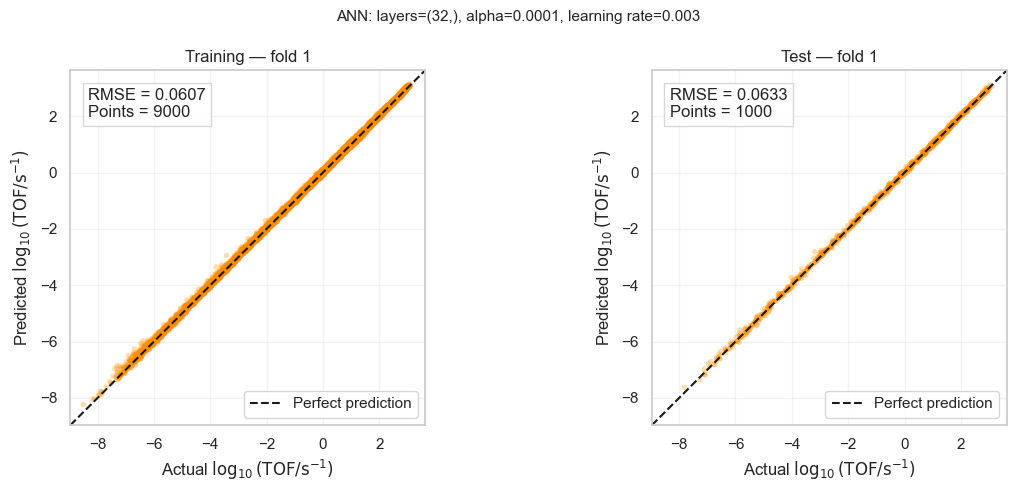


Final model fitted with internal early stopping.
Selected hyperparameters: {'alpha': 0.0001, 'hidden_layer_sizes': (32,), 'learning_rate_init': 0.003}
Results saved in: C:\Users\saish\Desktop\Desktop Stuff\ML_AI_projects\Microkinetic_data\ann_outputs


In [ ]:
# =====================================================================
# ARTIFICIAL NEURAL NETWORK: SIMPLE HYPERPARAMETER TUNING
# =====================================================================
#
# PURPOSE
# -------
# Predict turnover frequency (TOF) from temperature, pressure, and
# surface coverages using a feedforward artificial neural network.
#
# HYPERPARAMETER SEARCH
# ---------------------
# Test eight combinations:
#   hidden_layer_sizes : [(32,), (64, 32)]
#   alpha              : [0.0001, 0.01]
#   learning_rate_init : [0.001, 0.003]
#
# hidden_layer_sizes:
#   (32,)   = one hidden layer with 32 neurons.
#   (64,32) = two hidden layers with 64 and 32 neurons.
#
# alpha:
#   L2 regularisation strength. Larger values penalise large weights.
#
# learning_rate_init:
#   Initial step size used by the Adam optimiser.
#
# Other settings:
#   activation = "relu"
#   solver = "adam"
#   max_iter = 1000 training epochs
#   early_stopping = True
#
# CROSS-VALIDATION
# ----------------
# Evaluate each combination using identical shuffled 10-fold splits.
# For 10,000 rows, each outer fold contains:
#   9,000 training rows.
#   1,000 test rows.
#
# Early stopping reserves 10% of the outer training subset internally:
#   Approximately 8,100 rows for weight updates.
#   Approximately 900 rows for monitoring early stopping.
# The outer 1,000 test rows are never used for early stopping.
#
# Early stopping monitors internal R2, rather than RMSE. On a fixed
# internal subset, maximising R2 is equivalent to minimising squared
# error, although the stopping tolerance is expressed in R2 units.
#
# Average train/test RMSE across the ten folds.
# Select the combination with the LOWEST AVERAGE TEST RMSE.
#
# PREPROCESSING
# -------------
# A Pipeline standardises features within each fold.
# Scaling uses the outer training subset only.
#
# TARGET
# ------
# USE_LOG_TARGET=True:
#   Predict log10(TOF); RMSE is in log10 units.
#
# USE_LOG_TARGET=False:
#   Predict TOF; RMSE is in s^-1.
#
# The target is also standardised during fitting using
# TransformedTargetRegressor. Predictions are automatically returned
# to the selected target scale before calculating RMSE.
#
# PARITY PLOTS
# ------------
# Show fold 1 training/test predictions with the selected parameters.
# Training RMSE includes all outer training rows, including the
# internal early-stopping subset.
#
# NOTE
# ----
# These test folds also select hyperparameters, so their scores are
# tuning estimates rather than independent final test scores.
# ANN results depend on random initialisation.
# This search performs 80 ANN fits and may take several minutes.
#
# Dependencies:
# pip install pandas numpy matplotlib scikit-learn
# =====================================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import KFold, ParameterGrid
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor


# ---------------------------------------------------------------------
# 1. Settings
# ---------------------------------------------------------------------
INPUT_FILE = Path("methane_steam_reforming_data.csv")

OUTPUT_DIR = Path("ann_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

USE_LOG_TARGET = True
RANDOM_STATE = 42

features = [
    "temperature_K",
    "pressure_bar",
    "coverage_CH",
    "coverage_C",
    "coverage_OH",
    "coverage_O",
    "coverage_CO",
]

target = "TOF_s-1"


# ---------------------------------------------------------------------
# 2. Load and check data
# ---------------------------------------------------------------------
df = pd.read_csv(INPUT_FILE)

missing_columns = set(features + [target]) - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")

data = df[features + [target]].apply(pd.to_numeric, errors="raise")

X = data[features].to_numpy(dtype=float)
y = data[target].to_numpy(dtype=float)

if not np.isfinite(X).all() or not np.isfinite(y).all():
    raise ValueError("Data contain missing or infinite values.")

if len(data) < 30:
    raise ValueError("At least 30 rows are required for this CV setup.")

if USE_LOG_TARGET:
    if (y <= 0).any():
        raise ValueError("TOF must be positive for log10 transformation.")
    y = np.log10(y)

print(f"Dataset shape: {data.shape}")
print("Target:", "log10(TOF)" if USE_LOG_TARGET else "TOF")


# ---------------------------------------------------------------------
# 3. Define hyperparameters and identical 10-fold splits
# ---------------------------------------------------------------------
param_grid = {
    "hidden_layer_sizes": [(32,), (64, 32)],
    "alpha": [0.0001, 0.01],
    "learning_rate_init": [0.001, 0.003],
}

parameter_combinations = list(ParameterGrid(param_grid))

cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=RANDOM_STATE,
)

splits = list(cv.split(X))

print(f"\nParameter combinations: {len(parameter_combinations)}")
print(f"Folds per combination: {len(splits)}")


def make_model(params):
    """Create an ANN with feature and target standardisation."""
    feature_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        (
            "ann",
            MLPRegressor(
                **params,
                activation="relu",
                solver="adam",
                batch_size="auto",
                max_iter=1000,
                early_stopping=True,
                validation_fraction=0.10,
                n_iter_no_change=30,
                tol=1e-5,
                random_state=RANDOM_STATE,
            ),
        ),
    ])

    # Automatically standardise y during fitting and undo that scaling
    # during prediction. This does not undo the optional log10 transform.
    return TransformedTargetRegressor(
        regressor=feature_pipeline,
        transformer=StandardScaler(),
    )


# ---------------------------------------------------------------------
# 4. Evaluate every combination
# ---------------------------------------------------------------------
results = []

for combination_id, params in enumerate(parameter_combinations):
    print(
        f"\nCombination {combination_id + 1}/"
        f"{len(parameter_combinations)}: {params}",
        flush=True,
    )

    train_rmse_scores = []
    test_rmse_scores = []

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        model = make_model(params)
        model.fit(X[train_idx], y[train_idx])

        train_predictions = model.predict(X[train_idx])
        test_predictions = model.predict(X[test_idx])

        train_rmse = np.sqrt(
            mean_squared_error(y[train_idx], train_predictions)
        )
        test_rmse = np.sqrt(
            mean_squared_error(y[test_idx], test_predictions)
        )

        train_rmse_scores.append(train_rmse)
        test_rmse_scores.append(test_rmse)

        print(
            f"  Fold {fold:02d}: "
            f"train RMSE={train_rmse:.4f}, "
            f"test RMSE={test_rmse:.4f}",
            flush=True,
        )

    mean_train_rmse = np.mean(train_rmse_scores)
    mean_test_rmse = np.mean(test_rmse_scores)

    results.append({
        "Combination": combination_id,
        "hidden_layer_sizes": str(params["hidden_layer_sizes"]),
        "alpha": params["alpha"],
        "learning_rate_init": params["learning_rate_init"],
        "Mean_train_RMSE": mean_train_rmse,
        "Mean_test_RMSE": mean_test_rmse,
    })

    print(
        f"Average train RMSE: {mean_train_rmse:.4f} | "
        f"Average test RMSE: {mean_test_rmse:.4f}",
        flush=True,
    )


# ---------------------------------------------------------------------
# 5. Select the lowest average test RMSE
# ---------------------------------------------------------------------
results_df = (
    pd.DataFrame(results)
    .sort_values("Mean_test_RMSE", kind="stable")
    .reset_index(drop=True)
)

print("\nResults — lowest average test RMSE first:")
print(
    results_df.drop(columns="Combination")
    .round(5)
    .to_string(index=False)
)

best_result = results_df.iloc[0]
best_params = parameter_combinations[
    int(best_result["Combination"])
]

print("\nSELECTED HYPERPARAMETERS")
print(best_params)
print(f"Average train RMSE: {best_result['Mean_train_RMSE']:.4f}")
print(f"Average test RMSE:  {best_result['Mean_test_RMSE']:.4f}")

results_df.drop(columns="Combination").to_csv(
    OUTPUT_DIR / "hyperparameter_results.csv",
    index=False,
)


# ---------------------------------------------------------------------
# 6. Fit fold 1 using the selected hyperparameters
# ---------------------------------------------------------------------
train_idx, test_idx = splits[0]

fold_model = make_model(best_params)
fold_model.fit(X[train_idx], y[train_idx])

train_predictions = fold_model.predict(X[train_idx])
test_predictions = fold_model.predict(X[test_idx])

fold_train_rmse = np.sqrt(
    mean_squared_error(y[train_idx], train_predictions)
)
fold_test_rmse = np.sqrt(
    mean_squared_error(y[test_idx], test_predictions)
)

# Access the fitted ANN through the target transformer and pipeline.
fitted_ann = fold_model.regressor_.named_steps["ann"]

print("\nFOLD 1 RESULTS")
print(f"Outer training rows: {len(train_idx)}")
print(f"Test rows: {len(test_idx)}")
print(f"Train RMSE: {fold_train_rmse:.4f}")
print(f"Test RMSE:  {fold_test_rmse:.4f}")
print(f"Training epochs completed: {fitted_ann.n_iter_}")


# ---------------------------------------------------------------------
# 7. Plot training and test parity for fold 1
# ---------------------------------------------------------------------
target_label = (
    r"$\log_{10}(\mathrm{TOF}/\mathrm{s}^{-1})$"
    if USE_LOG_TARGET
    else r"TOF ($\mathrm{s}^{-1}$)"
)

all_values = np.concatenate([
    y[train_idx],
    y[test_idx],
    train_predictions,
    test_predictions,
])

lower = all_values.min()
upper = all_values.max()
padding = 0.04 * (upper - lower) if upper > lower else 1.0
limits = [lower - padding, upper + padding]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_data = [
    (
        y[train_idx],
        train_predictions,
        fold_train_rmse,
        "Training — fold 1",
    ),
    (
        y[test_idx],
        test_predictions,
        fold_test_rmse,
        "Test — fold 1",
    ),
]

for ax, (actual, predicted, rmse, title) in zip(axes, plot_data):
    ax.scatter(
        actual,
        predicted,
        s=15,
        alpha=0.3,
        color="darkorange",
        edgecolors="none",
    )

    ax.plot(
        limits,
        limits,
        "k--",
        linewidth=1.5,
        label="Perfect prediction",
    )

    ax.text(
        0.05,
        0.95,
        f"RMSE = {rmse:.4f}\nPoints = {len(actual)}",
        transform=ax.transAxes,
        va="top",
        bbox=dict(
            facecolor="white",
            alpha=0.9,
            edgecolor="lightgray",
        ),
    )

    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(f"Actual {target_label}")
    ax.set_ylabel(f"Predicted {target_label}")
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(loc="lower right")

fig.suptitle(
    "ANN: "
    f"layers={best_params['hidden_layer_sizes']}, "
    f"alpha={best_params['alpha']}, "
    f"learning rate={best_params['learning_rate_init']}",
    fontsize=11,
)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "selected_parameters_fold1_parity.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


# ---------------------------------------------------------------------
# 8. Fit the final model using all available rows
# ---------------------------------------------------------------------
# All rows enter the fitting procedure, but early stopping internally
# reserves 10% for monitoring and uses 90% for weight updates.
final_model = make_model(best_params)
final_model.fit(X, y)

print("\nFinal model fitted with internal early stopping.")
print(f"Selected hyperparameters: {best_params}")
print(f"Results saved in: {OUTPUT_DIR.resolve()}")

# Future predictions:
# predicted_target = final_model.predict(new_data[features].to_numpy())
#
# If USE_LOG_TARGET=True, convert predictions back to TOF:
# predicted_tof = 10.0 *b* predicted_target

SELECTED HYPERPARAMETERS
Decision tree: {'max_depth': None, 'min_samples_leaf': 20}
Random forest: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1}
ANN: {'hidden_layer_sizes': (32,), 'alpha': 0.0001, 'learning_rate_init': 0.003}

Dataset rows: 10000
Target: log10(TOF)

Evaluating Linear regression...
  Fold 01: train RMSE=0.7297, test RMSE=0.7359
  Fold 02: train RMSE=0.7304, test RMSE=0.7307
  Fold 03: train RMSE=0.7276, test RMSE=0.7547
  Fold 04: train RMSE=0.7294, test RMSE=0.7387
  Fold 05: train RMSE=0.7311, test RMSE=0.7237
  Fold 06: train RMSE=0.7329, test RMSE=0.7073
  Fold 07: train RMSE=0.7316, test RMSE=0.7190
  Fold 08: train RMSE=0.7288, test RMSE=0.7445
  Fold 09: train RMSE=0.7326, test RMSE=0.7104
  Fold 10: train RMSE=0.7288, test RMSE=0.7441

Evaluating Decision tree...
  Fold 01: train RMSE=0.2622, test RMSE=0.3316
  Fold 02: train RMSE=0.2642, test RMSE=0.3467
  Fold 03: train RMSE=0.2654, test RMSE=0.3090
  Fold 04: train RMSE=0.2606, test RMSE=0.3

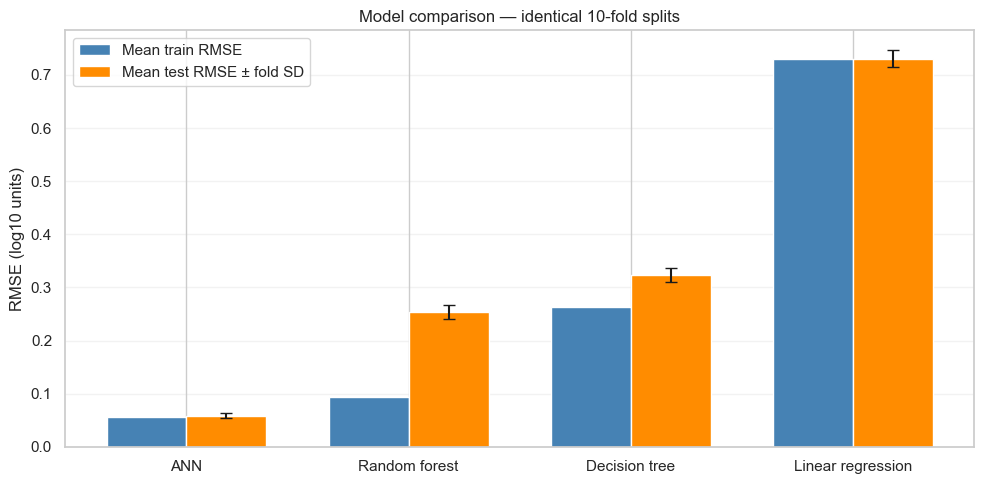

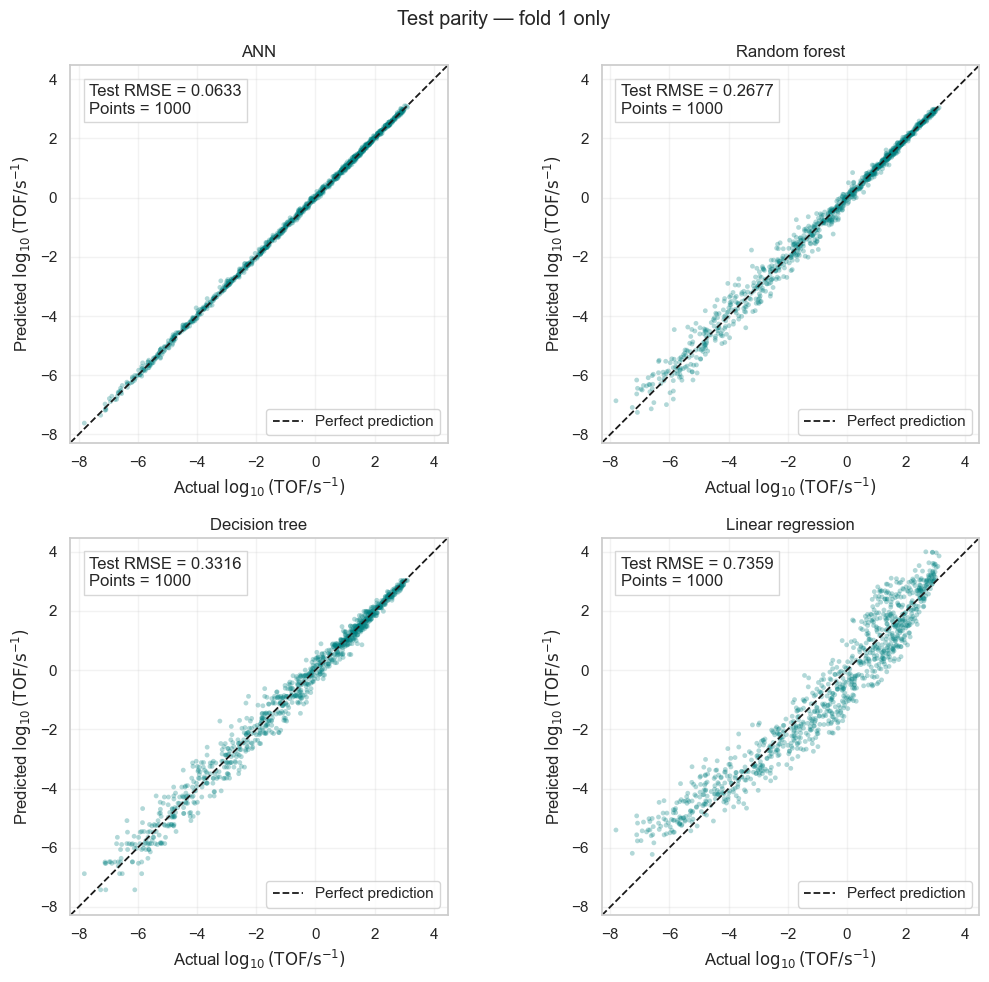


MODEL COMPARISON ANALYSIS

Accuracy winner in this comparison: ANN.
Its average test RMSE is 0.0589 log10 units, compared with 0.2544 for Random forest.
This represents a 76.8% reduction in RMSE relative to the runner-up.
The winner's average training RMSE is 0.0570, and its average test R2 is 0.9995.

Training/test RMSE gaps:
  ANN: train=0.0570, test=0.0589, gap=0.0019.
  Random forest: train=0.0946, test=0.2544, gap=0.1598.
  Decision tree: train=0.2630, test=0.3230, gap=0.0600.
  Linear regression: train=0.7303, test=0.7309, gap=0.0006.

A larger positive gap can indicate overfitting. A small gap alone does not establish a good model: both errors may still be high.
For the ANN, training RMSE includes its internal early-stopping subset, so its gap is not strictly equivalent to the other models' training/test gaps.

The ANN captures nonlinear relationships but requires scaling and may vary with random initialisation.
Recommendation: choose ANN if the main objective is the lowest RMS

In [16]:
# =====================================================================
# COMPARISON: LINEAR REGRESSION, DECISION TREE, RANDOM FOREST AND ANN
# =====================================================================
#
# PURPOSE
# -------
# Compare the four models using the hyperparameters selected previously.
#
# INPUT FILES
# -----------
# methane_steam_reforming_data.csv
# decision_tree_outputs/hyperparameter_results.csv
# random_forest_outputs/hyperparameter_results.csv
# ann_outputs/hyperparameter_results.csv
#
# PROCEDURE
# ---------
# 1. Load the winning hyperparameters from each saved tuning table.
# 2. Evaluate all models using identical shuffled 10-fold splits.
# 3. Calculate average training RMSE, test RMSE and test R2.
# 4. Rank models by lowest average test RMSE.
# 5. Show test parity plots for fold 1 only.
# 6. Print an analysis based on the calculated results.
#
# For 10,000 rows, each fold contains:
#   9,000 training rows.
#   1,000 test rows.
#
# TARGET
# ------
# USE_LOG_TARGET=True:
#   Predict log10(TOF); RMSE is measured in log10 units.
#
# USE_LOG_TARGET=False:
#   Predict TOF directly; RMSE is measured in s^-1.
#
# Use the SAME target setting used during your earlier tuning.
#
# PREPROCESSING
# -------------
# Linear regression and ANN use feature standardisation.
# Scaling is fitted separately within each outer training fold.
# ANN also uses target standardisation, automatically reversed when
# predicting. Its internal early-stopping subset comes only from the
# outer training data.
#
# INTERPRETATION
# --------------
# The lowest average test RMSE identifies the accuracy winner here.
# Training/test gaps help assess overfitting.
# Fold standard deviations describe variability, not confidence intervals.
#
# The same CV folds were previously used to select hyperparameters.
# These results therefore describe tuning performance rather than an
# independent final test assessment.
#
# Dependencies:
# pip install pandas numpy matplotlib scikit-learn
# =====================================================================

import ast
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor


# ---------------------------------------------------------------------
# 1. Settings
# ---------------------------------------------------------------------
INPUT_FILE = Path("methane_steam_reforming_data.csv")

OUTPUT_DIR = Path("model_comparison_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

USE_LOG_TARGET = True
RANDOM_STATE = 42

features = [
    "temperature_K",
    "pressure_bar",
    "coverage_CH",
    "coverage_C",
    "coverage_OH",
    "coverage_O",
    "coverage_CO",
]

target = "TOF_s-1"


# ---------------------------------------------------------------------
# 2. Load selected hyperparameters from earlier tuning results
# ---------------------------------------------------------------------
def load_best_result(file_path):
    """Return the row with the lowest average test RMSE."""
    file_path = Path(file_path)

    if not file_path.exists():
        raise FileNotFoundError(
            f"Cannot find {file_path}. "
            "Run the corresponding model's tuning cell first."
        )

    results = pd.read_csv(file_path, keep_default_na=False)

    if "Mean_test_RMSE" not in results.columns:
        raise ValueError(
            f"{file_path} does not contain 'Mean_test_RMSE'. "
            "Use the results from the simple 10-fold tuning code."
        )

    results["Mean_test_RMSE"] = pd.to_numeric(
        results["Mean_test_RMSE"],
        errors="raise",
    )

    if not np.isfinite(results["Mean_test_RMSE"]).all():
        raise ValueError(f"Invalid test RMSE values in {file_path}.")

    return results.sort_values(
        "Mean_test_RMSE",
        kind="stable",
    ).iloc[0]


def parse_depth(value):
    """Convert saved depth values into None or an integer."""
    if pd.isna(value) or str(value).strip().lower() in {
        "none", "nan", ""
    }:
        return None

    return int(float(value))


dt_best = load_best_result(
    "decision_tree_outputs/hyperparameter_results.csv"
)

DT_PARAMS = {
    "max_depth": parse_depth(dt_best["max_depth"]),
    "min_samples_leaf": int(dt_best["min_samples_leaf"]),
}


rf_best = load_best_result(
    "random_forest_outputs/hyperparameter_results.csv"
)

RF_PARAMS = {
    "n_estimators": int(rf_best["n_estimators"]),
    "max_depth": parse_depth(rf_best["max_depth"]),
    "min_samples_leaf": int(rf_best["min_samples_leaf"]),
}


ann_best = load_best_result(
    "ann_outputs/hyperparameter_results.csv"
)

ANN_PARAMS = {
    "hidden_layer_sizes": ast.literal_eval(
        str(ann_best["hidden_layer_sizes"])
    ),
    "alpha": float(ann_best["alpha"]),
    "learning_rate_init": float(ann_best["learning_rate_init"]),
}

print("SELECTED HYPERPARAMETERS")
print("Decision tree:", DT_PARAMS)
print("Random forest:", RF_PARAMS)
print("ANN:", ANN_PARAMS)


# ---------------------------------------------------------------------
# 3. Load and check dataset
# ---------------------------------------------------------------------
df = pd.read_csv(INPUT_FILE)

missing_columns = set(features + [target]) - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")

data = df[features + [target]].apply(pd.to_numeric, errors="raise")

X = data[features].to_numpy(dtype=float)
y = data[target].to_numpy(dtype=float)

if not np.isfinite(X).all() or not np.isfinite(y).all():
    raise ValueError("Data contain missing or infinite values.")

if len(data) < 30:
    raise ValueError("At least 30 rows are required for this CV setup.")

if USE_LOG_TARGET:
    if (y <= 0).any():
        raise ValueError("TOF must be positive for log10 transformation.")

    y = np.log10(y)

target_description = "log10(TOF)" if USE_LOG_TARGET else "TOF"
rmse_units = "log10 units" if USE_LOG_TARGET else "s^-1"

target_label = (
    r"$\log_{10}(\mathrm{TOF}/\mathrm{s}^{-1})$"
    if USE_LOG_TARGET
    else r"TOF ($\mathrm{s}^{-1}$)"
)

print(f"\nDataset rows: {len(data)}")
print(f"Target: {target_description}")


# ---------------------------------------------------------------------
# 4. Define models using the previously selected parameters
# ---------------------------------------------------------------------
models = {
    "Linear regression": Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", LinearRegression()),
    ]),

    "Decision tree": DecisionTreeRegressor(
        **DT_PARAMS,
        random_state=RANDOM_STATE,
    ),

    "Random forest": RandomForestRegressor(
        **RF_PARAMS,
        max_features=1.0,
        bootstrap=True,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),

    "ANN": TransformedTargetRegressor(
        regressor=Pipeline([
            ("scaler", StandardScaler()),
            (
                "ann",
                MLPRegressor(
                    **ANN_PARAMS,
                    activation="relu",
                    solver="adam",
                    batch_size="auto",
                    max_iter=1000,
                    early_stopping=True,
                    validation_fraction=0.10,
                    n_iter_no_change=30,
                    tol=1e-5,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]),
        transformer=StandardScaler(),
    ),
}


# ---------------------------------------------------------------------
# 5. Evaluate all models using identical 10-fold splits
# ---------------------------------------------------------------------
cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=RANDOM_STATE,
)

splits = list(cv.split(X))

fold_records = []
fold1_predictions = {}

for model_name, estimator in models.items():
    print(f"\nEvaluating {model_name}...", flush=True)

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        model = clone(estimator)

        start_time = perf_counter()
        model.fit(X[train_idx], y[train_idx])
        fit_seconds = perf_counter() - start_time

        train_predictions = model.predict(X[train_idx])
        test_predictions = model.predict(X[test_idx])

        train_rmse = np.sqrt(
            mean_squared_error(y[train_idx], train_predictions)
        )
        test_rmse = np.sqrt(
            mean_squared_error(y[test_idx], test_predictions)
        )
        test_r2 = r2_score(y[test_idx], test_predictions)

        fold_records.append({
            "Model": model_name,
            "Fold": fold,
            "Train_RMSE": train_rmse,
            "Test_RMSE": test_rmse,
            "Test_R2": test_r2,
            "Fit_seconds": fit_seconds,
        })

        # Store only fold 1 for the parity plots.
        if fold == 1:
            fold1_predictions[model_name] = {
                "actual": y[test_idx].copy(),
                "predicted": test_predictions.copy(),
                "rmse": test_rmse,
            }

        print(
            f"  Fold {fold:02d}: "
            f"train RMSE={train_rmse:.4f}, "
            f"test RMSE={test_rmse:.4f}",
            flush=True,
        )


# ---------------------------------------------------------------------
# 6. Rank models by average test RMSE
# ---------------------------------------------------------------------
fold_results = pd.DataFrame(fold_records)

comparison = (
    fold_results.groupby("Model", sort=False)
    .agg(
        Mean_train_RMSE=("Train_RMSE", "mean"),
        Mean_test_RMSE=("Test_RMSE", "mean"),
        SD_test_RMSE=("Test_RMSE", "std"),
        Mean_test_R2=("Test_R2", "mean"),
        Mean_fit_seconds=("Fit_seconds", "mean"),
    )
)

comparison["Test_minus_train_RMSE"] = (
    comparison["Mean_test_RMSE"]
    - comparison["Mean_train_RMSE"]
)

comparison = comparison.sort_values(
    "Mean_test_RMSE",
    kind="stable",
)

print(f"\nMODEL COMPARISON — RMSE in {rmse_units}")
print(comparison.round(4).to_string())


# ---------------------------------------------------------------------
# 7. Plot average training and test RMSE
# ---------------------------------------------------------------------
positions = np.arange(len(comparison))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    positions - width / 2,
    comparison["Mean_train_RMSE"],
    width,
    label="Mean train RMSE",
    color="steelblue",
)

ax.bar(
    positions + width / 2,
    comparison["Mean_test_RMSE"],
    width,
    yerr=comparison["SD_test_RMSE"],
    capsize=4,
    label="Mean test RMSE ± fold SD",
    color="darkorange",
)

ax.set_xticks(positions)
ax.set_xticklabels(comparison.index)
ax.set_ylabel(f"RMSE ({rmse_units})")
ax.set_title("Model comparison — identical 10-fold splits")
ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "model_rmse_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


# ---------------------------------------------------------------------
# 8. Test parity plots for fold 1 only
# ---------------------------------------------------------------------
# All panels show predictions for exactly the same held-out rows.
all_values = np.concatenate([
    values
    for model_data in fold1_predictions.values()
    for values in (
        model_data["actual"],
        model_data["predicted"],
    )
])

lower = all_values.min()
upper = all_values.max()
padding = 0.04 * (upper - lower) if upper > lower else 1.0
limits = [lower - padding, upper + padding]

fig, axes = plt.subplots(2, 2, figsize=(11, 10))

for ax, model_name in zip(axes.flat, comparison.index):
    values = fold1_predictions[model_name]

    ax.scatter(
        values["actual"],
        values["predicted"],
        s=12,
        alpha=0.3,
        color="teal",
        edgecolors="none",
    )

    ax.plot(
        limits,
        limits,
        "k--",
        linewidth=1.3,
        label="Perfect prediction",
    )

    ax.text(
        0.05,
        0.95,
        (
            f"Test RMSE = {values['rmse']:.4f}\n"
            f"Points = {len(values['actual'])}"
        ),
        transform=ax.transAxes,
        va="top",
        bbox=dict(
            facecolor="white",
            alpha=0.9,
            edgecolor="lightgray",
        ),
    )

    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(model_name)
    ax.set_xlabel(f"Actual {target_label}")
    ax.set_ylabel(f"Predicted {target_label}")
    ax.grid(alpha=0.25)
    ax.legend(loc="lower right")

fig.suptitle("Test parity — fold 1 only")
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "fold1_test_parity_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


# ---------------------------------------------------------------------
# 9. Generate a results-based analysis
# ---------------------------------------------------------------------
winner = comparison.index[0]
runner_up = comparison.index[1]

winner_rmse = comparison.loc[winner, "Mean_test_RMSE"]
runner_up_rmse = comparison.loc[runner_up, "Mean_test_RMSE"]

relative_improvement = (
    100 * (runner_up_rmse - winner_rmse) / runner_up_rmse
    if runner_up_rmse > 0
    else 0.0
)

analysis = [
    "MODEL COMPARISON ANALYSIS",
    "",
    f"Accuracy winner in this comparison: {winner}.",
    (
        f"Its average test RMSE is {winner_rmse:.4f} {rmse_units}, "
        f"compared with {runner_up_rmse:.4f} for {runner_up}."
    ),
    (
        f"This represents a {relative_improvement:.1f}% reduction "
        "in RMSE relative to the runner-up."
    ),
    (
        f"The winner's average training RMSE is "
        f"{comparison.loc[winner, 'Mean_train_RMSE']:.4f}, "
        f"and its average test R2 is "
        f"{comparison.loc[winner, 'Mean_test_R2']:.4f}."
    ),
    "",
    "Training/test RMSE gaps:",
]

for model_name, row in comparison.iterrows():
    analysis.append(
        f"  {model_name}: "
        f"train={row['Mean_train_RMSE']:.4f}, "
        f"test={row['Mean_test_RMSE']:.4f}, "
        f"gap={row['Test_minus_train_RMSE']:.4f}."
    )

analysis.extend([
    "",
    (
        "A larger positive gap can indicate overfitting. "
        "A small gap alone does not establish a good model: both errors "
        "may still be high."
    ),
    (
        "For the ANN, training RMSE includes its internal early-stopping "
        "subset, so its gap is not strictly equivalent to the other "
        "models' training/test gaps."
    ),
])

model_notes = {
    "Linear regression": (
        "Linear regression offers the simplest functional form and "
        "a useful baseline."
    ),
    "Decision tree": (
        "The decision tree captures nonlinear interactions and can be "
        "inspected, although predictions are piecewise constant."
    ),
    "Random forest": (
        "Random forest captures nonlinear interactions by averaging "
        "many trees and requires no feature scaling."
    ),
    "ANN": (
        "The ANN captures nonlinear relationships but requires scaling "
        "and may vary with random initialisation."
    ),
}

analysis.extend([
    "",
    model_notes[winner],
    (
        f"Recommendation: choose {winner} if the main objective is "
        "the lowest RMSE among these tested configurations."
    ),
    (
        "If leading models have similar errors, also consider simplicity "
        "and computational cost. Fit times here are approximate and "
        "depend on the computer and available CPU cores."
    ),
    (
        "Fold standard deviations are not confidence intervals and do "
        "not establish statistical significance."
    ),
    (
        "These scores reuse the folds used for hyperparameter selection. "
        "An independent test set is needed for a separate final "
        "performance assessment."
    ),
    (
        "Results describe predictive performance on this generated "
        "dataset and do not validate real catalyst behaviour."
    ),
])

analysis_text = "\n".join(analysis)
print("\n" + analysis_text)


# ---------------------------------------------------------------------
# 10. Save tables and analysis
# ---------------------------------------------------------------------
fold_results.to_csv(
    OUTPUT_DIR / "all_model_fold_metrics.csv",
    index=False,
)

comparison.to_csv(
    OUTPUT_DIR / "model_comparison_summary.csv",
)

(OUTPUT_DIR / "model_comparison_analysis.txt").write_text(
    analysis_text,
    encoding="utf-8",
)

print(f"\nResults saved in: {OUTPUT_DIR.resolve()}")